# 10 — Indoor mapping (pengganti CGA split lantai/ruang)

1. Pilih satu gedung OSM (nama memuat `indoor.name_contains` di config; kosong = gedung terbesar).
2. Split per lantai: lantai dasar `GFl`, lantai berikutnya `Fl`, total `levels` lantai.
3. Tiap lantai: koridor di sumbu panjang `minimum_rotated_rectangle`, ruang di kedua sisi selebar ±6 m.
4. Atribut `BlockName`, `BlockNo`, `FloorNo`, `RoomNo`, `RoomUse` (**asumsi**; ganti dengan data denah bila ada).
5. Visual 3D dengan tooltip identify (setara Fig. 25) dan contoh query "ruang lab di lantai 2".

**Output**: `output/indoor_<gedung>.gpkg`, `output/indoor_<gedung>.glb`, `output/indoor_<gedung>.html`.

In [1]:
import re

import geopandas as gpd
import numpy as np
import pandas as pd
import pydeck as pdk
import trimesh
from shapely import affinity
from shapely.geometry import box

from ui3d_common import CFG, CRS, out

I, Bc = CFG["indoor"], CFG["building"]
GFl, Fl = Bc["GFl"], Bc["Fl"]
bld = gpd.read_file(out("ui3d.gpkg"), layer="buildings")
bld = bld[bld.geom_type == "Polygon"]

## 1. Pilih gedung

Dekanat FTUI: 808 m², lantai=2, Bld_Height=8.5 m


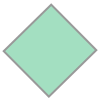

In [2]:
cand = bld[bld["name"].fillna("").str.contains(I["name_contains"], case=False)] if I["name_contains"] else bld.iloc[:0]
pick = (cand if len(cand) else bld).sort_values("area_m2").iloc[-1]
name = pick["name"] or f"gedung_{pick['id']}"
slug = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
print(f"{name}: {pick.area_m2:.0f} m², lantai={pick.levels}, Bld_Height={pick.Bld_Height} m")
pick.geometry

## 2–3. Koridor dan ruang per lantai

Footprint diputar agar sisi panjang `minimum_rotated_rectangle` sejajar sumbu x, dibagi, lalu diputar balik.

In [3]:
fp = pick.geometry
mrr = np.asarray(fp.minimum_rotated_rectangle.exterior.coords)
edges = mrr[1:] - mrr[:-1]
e = edges[np.argmax(np.hypot(edges[:, 0], edges[:, 1]))]
angle = np.degrees(np.arctan2(e[1], e[0]))
c = fp.centroid
rot = affinity.rotate(fp, -angle, origin=c)
x0, y0, x1, y1 = rot.bounds
ym, hw = (y0 + y1) / 2, I["corridor_w_m"] / 2


def back(g):
    return affinity.rotate(g, angle, origin=c)


corridor = back(box(x0, ym - hw, x1, ym + hw).intersection(rot))
rooms = []
for xa in np.arange(x0, x1, I["room_w_m"]):
    xb = min(xa + I["room_w_m"], x1)
    for side, (ya, yb) in (("S", (y0, ym - hw)), ("N", (ym + hw, y1))):
        g = box(xa, ya, xb, yb).intersection(rot)
        if g.area >= I["min_room_m2"] and g.geom_type in ("Polygon", "MultiPolygon"):
            rooms.append((side, back(g)))
print(f"{len(rooms)} ruang per lantai")


def room_use(i, n):
    """Asumsi penggunaan ruang: ujung = toilet/tangga, sisanya bergantian kelas/lab/dosen."""
    if i in (0, n - 1):
        return "Toilet/Tangga"
    return ["Kelas", "Lab", "Ruang Dosen"][i % 3]


recs = []
for floor in range(1, int(pick.levels) + 1):
    z0 = 0.0 if floor == 1 else GFl + Fl * (floor - 2)
    h = GFl if floor == 1 else Fl
    for i, (side, g) in enumerate(rooms):
        recs.append(dict(BlockName=name, BlockNo=str(pick["id"]), FloorNo=floor, RoomNo=f"{floor}{i + 1:02d}",
                         RoomUse=room_use(i, len(rooms)), side=side, z0=z0, height=h, geometry=g))
    recs.append(dict(BlockName=name, BlockNo=str(pick["id"]), FloorNo=floor, RoomNo=f"{floor}K", RoomUse="Koridor",
                     side="-", z0=z0, height=h, geometry=corridor))
indoor = gpd.GeoDataFrame(recs, crs=CRS)
indoor["area_m2"] = indoor.area.round(1)
indoor.to_file(out(f"indoor_{slug}.gpkg"), layer="rooms")
indoor.drop(columns="geometry").head(12)

10 ruang per lantai


,BlockName,BlockNo,FloorNo,RoomNo,RoomUse,side,z0,height,area_m2
0,Dekanat FTUI,151282513,1,101,Toilet/Tangga,S,0.0,4.0,74.5
1,Dekanat FTUI,151282513,1,102,Lab,N,0.0,4.0,75.7
2,Dekanat FTUI,151282513,1,103,Ruang Dosen,S,0.0,4.0,76.3
3,Dekanat FTUI,151282513,1,104,Kelas,N,0.0,4.0,76.2
4,Dekanat FTUI,151282513,1,105,Lab,S,0.0,4.0,76.3
5,Dekanat FTUI,151282513,1,106,Ruang Dosen,N,0.0,4.0,76.2
6,Dekanat FTUI,151282513,1,107,Kelas,S,0.0,4.0,76.3
7,Dekanat FTUI,151282513,1,108,Lab,N,0.0,4.0,76.2
8,Dekanat FTUI,151282513,1,109,Ruang Dosen,S,0.0,4.0,64.8
9,Dekanat FTUI,151282513,1,110,Toilet/Tangga,N,0.0,4.0,63.5


## Contoh query: ruang lab di lantai 2

In [4]:
q = indoor[(indoor.RoomUse == "Lab") & (indoor.FloorNo == 2)]
q[["RoomNo", "RoomUse", "FloorNo", "area_m2"]]

,RoomNo,RoomUse,FloorNo,area_m2
12,202,Lab,2,75.7
15,205,Lab,2,76.3
18,208,Lab,2,76.2


## Model 3D per lantai (glb) dan viewer identify (setara Fig. 25)

In [5]:
USE_COLORS = {"Kelas": [66, 133, 244], "Lab": [219, 68, 55], "Ruang Dosen": [15, 157, 88],
              "Toilet/Tangga": [158, 158, 158], "Koridor": [240, 230, 200]}
scene = trimesh.Scene()
for _, r in indoor.iterrows():
    for g in getattr(r.geometry, "geoms", [r.geometry]):
        if g.geom_type != "Polygon" or g.is_empty:
            continue
        m = trimesh.creation.extrude_polygon(affinity.translate(g, -c.x, -c.y), r.height - 0.15)
        m.apply_translation([0, 0, r.z0])
        m.visual.face_colors = USE_COLORS[r.RoomUse] + [255]
        scene.add_geometry(m, node_name=f"F{r.FloorNo}_{r.RoomNo}")
scene.apply_transform(trimesh.transformations.rotation_matrix(-np.pi / 2, [1, 0, 0]))
scene.export(out(f"indoor_{slug}.glb"))

i4 = indoor.to_crs(4326).explode(index_parts=False)
i4 = i4[i4.geom_type == "Polygon"]
df = pd.DataFrame(i4.drop(columns="geometry"))
df["polygon"] = [[[p[0], p[1], z] for p in g.exterior.coords] for g, z in zip(i4.geometry, i4.z0)]
df["elev"] = df.height - 0.15
df["color"] = df.RoomUse.map(USE_COLORS)
cc = i4.union_all().centroid
deck = pdk.Deck(
    layers=[pdk.Layer("PolygonLayer", df, get_polygon="polygon", extruded=True, get_elevation="elev",
                      get_fill_color="color", opacity=0.6, pickable=True, auto_highlight=True)],
    initial_view_state=pdk.ViewState(longitude=cc.x, latitude=cc.y, zoom=18.5, pitch=60),
    map_provider="carto", map_style="light",
    tooltip={"html": "<b>{BlockName}</b><br/>Lantai {FloorNo} — Ruang {RoomNo}<br/>{RoomUse} ({area_m2} m²)"},
)
deck.to_html(str(out(f"indoor_{slug}.html")), open_browser=False)
deck

{
  "initialViewState": {
    "latitude": -6.361683583594629,
    "longitude": 106.824030566292,
    "pitch": 60,
    "zoom": 18.5
  },
  "layers": [
    {
      "@@type": "PolygonLayer",
      "autoHighlight": true,
      "data": [
        {
          "BlockName": "Dekanat FTUI",
          "BlockNo": "151282513",
          "FloorNo": 1,
          "RoomNo": "101",
          "RoomUse": "Toilet/Tangga",
          "area_m2": 74.5,
          "color": [
            158,
            158,
            158
          ],
          "elev": 3.85,
          "height": 4.0,
          "polygon": [
            [
              106.82398336019097,
              -6.3617460096104645,
              0.0
            ],
            [
              106.8240640521203,
              -6.361827830367667,
              0.0
            ],
            [
              106.8240266,
              -6.361864799999993,
              0.0
            ],
            [
              106.82394538560023,
              -6.36178349458015,
              0.0
            ],
            [
              106.82398336019097,
              -6.3617460096104645,
              0.0
            ]
          ],
          "side": "S",
          "z0": 0.0
        },
        {
          "BlockName": "Dekanat FTUI",
          "BlockNo": "151282513",
          "FloorNo": 1,
          "RoomNo": "102",
          "RoomUse": "Lab",
          "area_m2": 75.7,
          "color": [
            219,
            68,
            55
          ],
          "elev": 3.85,
          "height": 4.0,
          "polygon": [
            [
              106.82396749166838,
              -6.3617299190920935,
              0.0
            ],
            [
              106.8239294143692,
              -6.361767505444156,
              0.0
            ],
            [
              106.8238482,
              -6.361686200000004,
              0.0
            ],
            [
              106.82388681994011,
              -6.361648118763333,
              0.0
            ],
            [
              106.82396749166838,
              -6.3617299190920935,
              0.0
            ]
          ],
          "side": "N",
          "z0": 0.0
        },
        {
          "BlockName": "Dekanat FTUI",
          "BlockNo": "151282513",
          "FloorNo": 1,
          "RoomNo": "103",
          "RoomUse": "Ruang Dosen",
          "area_m2": 76.3,
          "color": [
            15,
            157,
            88
          ],
          "elev": 3.85,
          "height": 4.0,
          "polygon": [
            [
              106.82398336019097,
              -6.3617460096104645,
              0.0
            ],
            [
              106.82402195975732,
              -6.3617079077163226,
              0.0
            ],
            [
              106.82410265148371,
              -6.361789728265124,
              0.0
            ],
            [
              106.8240640521203,
              -6.361827830367667,
              0.0
            ],
            [
              106.82398336019097,
              -6.3617460096104645,
              0.0
            ]
          ],
          "side": "S",
          "z0": 0.0
        },
        {
          "BlockName": "Dekanat FTUI",
          "BlockNo": "151282513",
          "FloorNo": 1,
          "RoomNo": "104",
          "RoomUse": "Kelas",
          "area_m2": 76.2,
          "color": [
            66,
            133,
            244
          ],
          "elev": 3.85,
          "height": 4.0,
          "polygon": [
            [
              106.82400609123538,
              -6.361691817199124,
              0.0
            ],
            [
              106.82396749166838,
              -6.3617299190920935,
              0.0
            ],
            [
              106.82388681994011,
              -6.361648118763333,
              0.0
            ],
            [
              106.82392543987451,
              -6.361610037525382,
              0.0
            ],